LECTURE-13

In [1]:
import pandas as pd
import numpy as np

df = pd.read_excel("/content/Starbucks_Stores_Data.xlsx", sheet_name="Stores")

print("Rows:", df.shape[0], "| Columns:", df.shape[1])

df.head()

Rows: 300 | Columns: 25


,Store_ID,City,City_Tier,Location_Type,Store_Area_SqFt,Seats,Staff_Count,Social_Media_Spend_K,Outdoor_Ad_Spend_K,Influencer_Spend_K,...,Taste_Score,Service_Score,Cleanliness_Score,Ambience_Score,Staff_Friendliness_Score,Avg_Wait_Time_Min,Monthly_Footfall_K,Avg_Bill_INR,Repeat_Customer_Pct,Monthly_Sales_INR_Lakh
0,ST-001,Hyderabad,Metro,Airport or Transit,790,37,9,129,136,46,...,5.6,4.9,5.7,6.2,6.1,5.0,14.5,281,35.3,79.2
1,ST-002,Nagpur,Tier 3,High Street,1400,50,14,95,34,28,...,6.8,7.1,7.1,6.3,7.0,6.2,14.7,280,40.4,79.9
2,ST-003,Kolkata,Metro,High Street,1120,44,10,76,78,53,...,9.0,8.8,9.4,8.8,8.5,3.5,16.1,362,46.1,84.1
3,ST-004,Delhi NCR,Metro,High Street,1830,67,19,53,57,23,...,6.8,6.8,7.2,7.2,7.2,4.8,15.9,291,39.5,85.9
4,ST-005,Chennai,Metro,Mall,1300,54,13,198,103,94,...,6.7,5.6,6.1,7.1,6.3,5.1,19.1,296,37.5,123.0


In [2]:
df.describe().round(1)

,Store_Area_SqFt,Seats,Staff_Count,Social_Media_Spend_K,Outdoor_Ad_Spend_K,Influencer_Spend_K,Promo_Offers_Count,App_Orders_Share_Pct,Loyalty_Members_K,App_Rating,...,Taste_Score,Service_Score,Cleanliness_Score,Ambience_Score,Staff_Friendliness_Score,Avg_Wait_Time_Min,Monthly_Footfall_K,Avg_Bill_INR,Repeat_Customer_Pct,Monthly_Sales_INR_Lakh
count,300.0,300.0,300.0,300.0,300.0,300.0,300.0,300.0,300.0,300.0,...,300.0,300.0,300.0,300.0,300.0,300.0,300.0,300.0,300.0,300.0
mean,1192.8,45.3,11.7,128.4,86.2,54.0,6.2,25.0,21.6,4.2,...,7.3,7.0,7.5,7.3,7.4,6.1,15.9,310.5,39.4,88.8
std,343.4,13.5,3.1,46.2,33.8,22.4,2.4,7.2,7.4,0.3,...,0.8,1.0,0.8,0.8,0.9,1.5,4.2,25.2,6.8,20.3
min,500.0,14.0,5.0,30.0,15.0,8.0,1.0,6.0,4.0,3.4,...,4.9,4.2,5.7,5.0,4.3,2.5,5.0,235.0,15.0,45.5
25%,950.0,37.0,9.0,95.0,62.8,39.8,4.0,20.3,16.6,4.1,...,6.8,6.3,7.0,6.8,6.8,5.0,12.9,294.0,35.2,75.6
50%,1210.0,45.0,12.0,127.0,85.0,54.0,6.0,25.8,22.0,4.2,...,7.3,7.0,7.4,7.3,7.3,6.0,15.9,310.0,40.0,86.1
75%,1440.0,54.0,14.0,158.0,109.0,69.0,8.0,30.0,26.5,4.4,...,7.8,7.7,8.0,7.7,8.0,7.2,18.6,327.0,44.0,98.1
max,2000.0,80.0,19.0,260.0,179.0,120.0,13.0,48.0,40.1,4.9,...,9.7,10.0,9.7,9.2,9.7,11.1,26.6,382.0,58.1,170.8


Which business variables do we want to relate and what type is each

In [3]:
numbers = df.select_dtypes(include="number").columns.tolist()

categories = df.select_dtypes(exclude="number").columns.tolist()

print("Number variables:", len(numbers))

print("Category variables:", categories)

Number variables: 21
Category variables: ['Store_ID', 'City', 'City_Tier', 'Location_Type']


In [4]:
# the nine key variable we will use in part C
key_cols = [
    "Social_Media_Spend_K",
    "App_Orders_Share_Pct",
    "Seats",
    "Staff_Count",
    "Avg_Wait_Time_Min",
    "Service_Score",
    "Repeat_Customer_Pct",
    "Monthly_Footfall_K",
    "Monthly_Sales_INR_Lakh"
]

print("Nine Key Variables:")
print(key_cols)

Nine Key Variables:
['Social_Media_Spend_K', 'App_Orders_Share_Pct', 'Seats', 'Staff_Count', 'Avg_Wait_Time_Min', 'Service_Score', 'Repeat_Customer_Pct', 'Monthly_Footfall_K', 'Monthly_Sales_INR_Lakh']


Do stores with a higher share of app orders sell more?

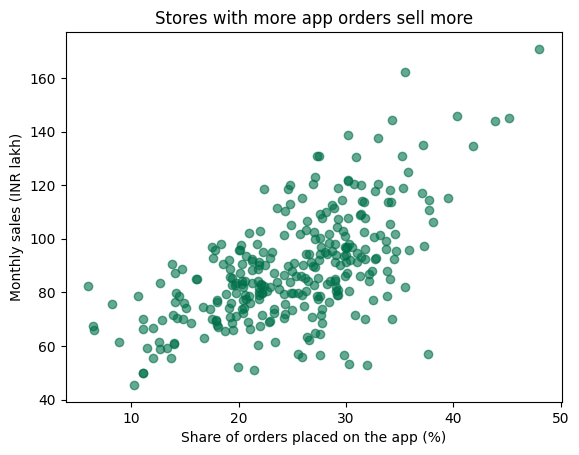

In [5]:
import matplotlib.pyplot as plt
plt.scatter(df["App_Orders_Share_Pct"], df["Monthly_Sales_INR_Lakh"], alpha=0.6, color="#00704A")
plt.title("Stores with more app orders sell more")
plt.xlabel("Share of orders placed on the app (%)")
plt.ylabel("Monthly sales (INR lakh)")
plt.show()

Negative Relationship- Do longer waits mean fewer repeat customers

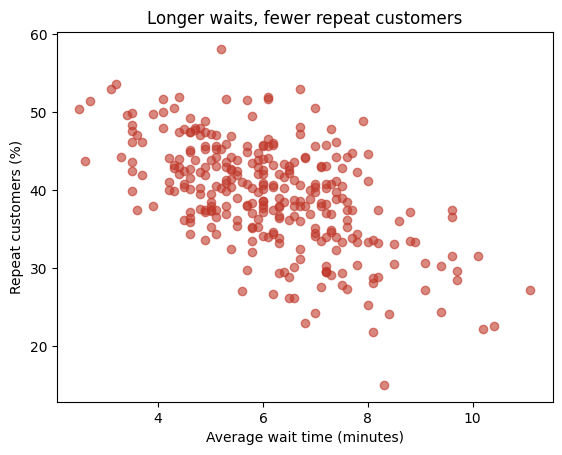

In [6]:
plt.scatter(df["Avg_Wait_Time_Min"], df["Repeat_Customer_Pct"], alpha=0.6, color="#C0392B")
plt.title("Longer waits, fewer repeat customers")
plt.xlabel("Average wait time (minutes)")
plt.ylabel("Repeat customers (%)")
plt.show()

Neutral Relationship/No relationship- Does a bigger store have a better coffee

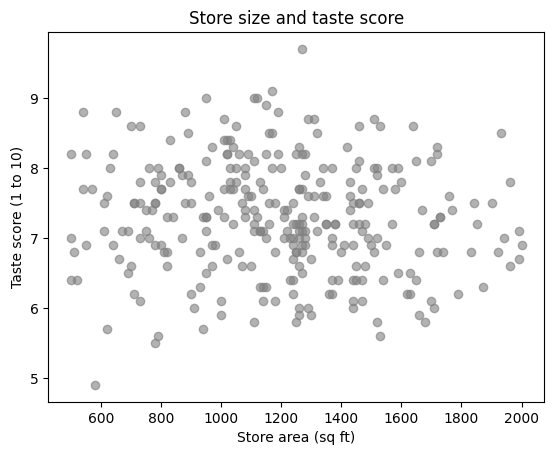

In [7]:
plt.scatter(df["Store_Area_SqFt"], df["Taste_Score"], alpha=0.6, color="grey")
plt.title("Store size and taste score")
plt.xlabel("Store area (sq ft)")
plt.ylabel("Taste score (1 to 10)")
plt.show()

COORELATION COEFFICIENT- How strong is the relationship and in which direction

In [8]:
r1 = df["App_Orders_Share_Pct"].corr(df["Monthly_Sales_INR_Lakh"])
r2 = df["Avg_Wait_Time_Min"].corr(df["Repeat_Customer_Pct"])
r3 = df["Store_Area_SqFt"].corr(df["Taste_Score"])

print("App share and sales       :", round(r1, 2))
print("Wait time and repeat      :", round(r2, 2))
print("Store area and taste      :", round(r3, 2))

App share and sales       : 0.61
Wait time and repeat      : -0.58
Store area and taste      : -0.09


How are all the key variables related to each other

In [9]:
corr=df[key_cols].corr().round(2)
corr

,Social_Media_Spend_K,App_Orders_Share_Pct,Seats,Staff_Count,Avg_Wait_Time_Min,Service_Score,Repeat_Customer_Pct,Monthly_Footfall_K,Monthly_Sales_INR_Lakh
Social_Media_Spend_K,1.00,0.40,-0.00,0.03,-0.01,-0.06,-0.02,0.32,0.67
App_Orders_Share_Pct,0.40,1.00,-0.03,-0.02,0.03,-0.03,-0.03,0.44,0.61
Seats,-0.00,-0.03,1.00,0.75,0.13,-0.09,-0.07,0.53,0.37
Staff_Count,0.03,-0.02,0.75,1.00,0.07,-0.01,-0.04,0.54,0.30
Avg_Wait_Time_Min,-0.01,0.03,0.13,0.07,1.00,-0.26,-0.58,-0.05,0.04
Service_Score,-0.06,-0.03,-0.09,-0.01,-0.26,1.00,0.75,0.25,-0.01
Repeat_Customer_Pct,-0.02,-0.03,-0.07,-0.04,-0.58,0.75,1.00,0.17,-0.01
Monthly_Footfall_K,0.32,0.44,0.53,0.54,-0.05,0.25,0.17,1.00,0.59
Monthly_Sales_INR_Lakh,0.67,0.61,0.37,0.30,0.04,-0.01,-0.01,0.59,1.00


where are the strong and weak relationship

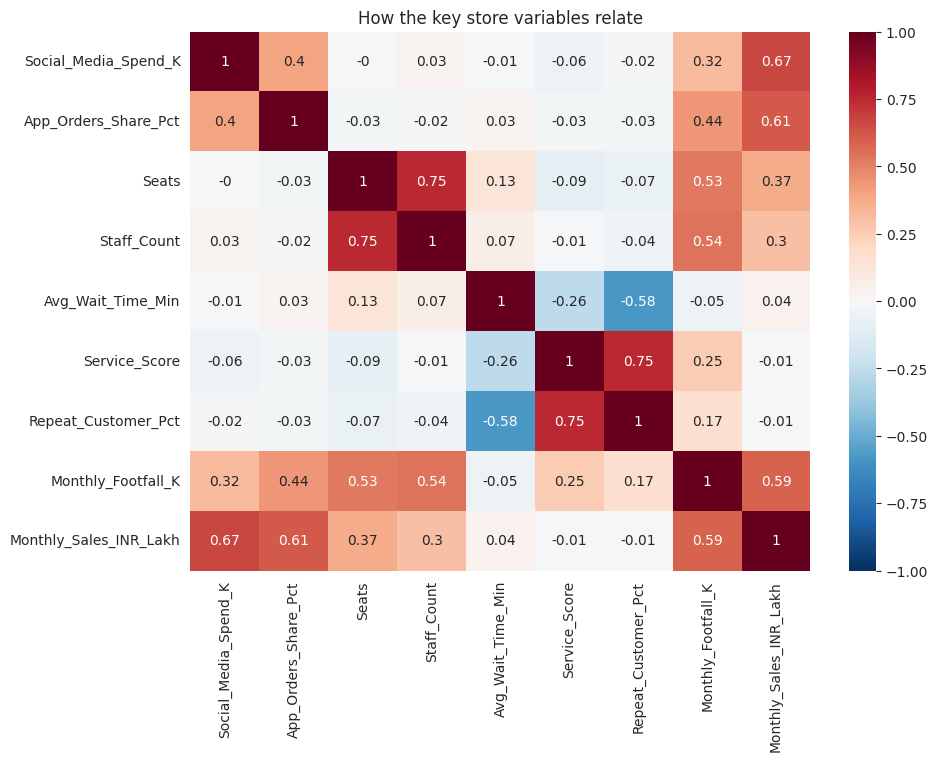

In [10]:
import seaborn as sns
sns.set_style("whitegrid")

plt.figure(figsize=(10, 7))
sns.heatmap(corr, annot=True, cmap="RdBu_r", vmin=-1, vmax=1)

plt.title("How the key store variables relate")
plt.show()

Statistical Modelling- Linear Regression-  Does social media spend rise sales and by how much

In [11]:
import statsmodels.formula.api as smf

m_social = smf.ols("Monthly_Sales_INR_Lakh ~ Social_Media_Spend_K", data=df).fit()

print(m_social.summary().tables[1])
print("R-squared:", round(m_social.rsquared, 2))

                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
Intercept               50.9018      2.574     19.775      0.000      45.836      55.967
Social_Media_Spend_K     0.2950      0.019     15.631      0.000       0.258       0.332
R-squared: 0.45


Interpretation - A unit increase in social media spending is associated with a rs 0.2950 lakh increase in monthly sales

Social media spending explains 45% of variation in monthly sales.

Social media spending as a statistically significant positive relationship with monthly sales.

MULTIPLE LINEAR REGRESSION - What are the effects of some other variables of monthly sales?

In [12]:
m_multi = smf.ols("Monthly_Sales_INR_Lakh ~ Social_Media_Spend_K + App_Orders_Share_Pct + Seats", data=df).fit()

print(m_multi.summary().tables[1])
print("R-squared:", round(m_multi.rsquared, 2))

                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
Intercept                4.8896      3.176      1.539      0.125      -1.361      11.140
Social_Media_Spend_K     0.2226      0.014     15.497      0.000       0.194       0.251
App_Orders_Share_Pct     1.1821      0.093     12.779      0.000       1.000       1.364
Seats                    0.5677      0.045     12.614      0.000       0.479       0.656
R-squared: 0.73


LECTURE-14: MULTIPLE LINEAR REGRESSION / MODERATION EFFECT /PCA

DOES STAFF COUNT STILL MATTER ONCE STORE SIZE IS HELD FIX

In [13]:
m_staff_alone = smf.ols("Monthly_Sales_INR_Lakh ~ Staff_Count", data=df).fit()
m_staff_ctrl = smf.ols("Monthly_Sales_INR_Lakh ~ Staff_Count + Seats", data=df).fit()

print(m_staff_alone.summary().tables[1])
print("R-squared:", round(m_staff_alone.rsquared, 2))

print(m_staff_ctrl.summary().tables[1])
print("R-squared:", round(m_staff_ctrl.rsquared, 2))

print("Staff effect alone:", round(m_staff_alone.params["Staff_Count"], 2),
      "| p-value:", round(m_staff_alone.pvalues["Staff_Count"], 3))

print("Staff effect with Seats:", round(m_staff_ctrl.params["Staff_Count"], 2),
      "| p-value:", round(m_staff_ctrl.pvalues["Staff_Count"], 3))

                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
Intercept      66.0724      4.371     15.115      0.000      57.470      74.675
Staff_Count     1.9441      0.362      5.371      0.000       1.232       2.656
R-squared: 0.09
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
Intercept      62.4999      4.354     14.356      0.000      53.932      71.068
Staff_Count     0.3474      0.530      0.656      0.512      -0.695       1.390
Seats           0.4907      0.121      4.043      0.000       0.252       0.730
R-squared: 0.14
Staff effect alone: 1.94 | p-value: 0.0
Staff effect with Seats: 0.35 | p-value: 0.512


Interpretation:

print("1. Staff Count alone has a positive and significant effect on sales "
      "(Coefficient = 1.9441, p < 0.001). It explains 9% of sales variation.")

print("2. After controlling for Seats, Staff Count becomes insignificant "
      "(Coefficient = 0.3474, p = 0.512).")

print("3. Seats has a positive and significant effect on sales "
      "(Coefficient = 0.4907, p < 0.001).")

print("4. R-squared increases from 0.09 to 0.14.")

print("\nConclusion: Seats is a significant predictor of monthly sales, "
      "while Staff Count is not significant after controlling for Seats.")

Does the effect of social media spending depends on how digital store is

In [14]:
#STEP-1 Centralisation of the variable
# Centre the numbers: subtract the average

df['Social_c'] = df['Social_Media_Spend_K'] - df['Social_Media_Spend_K'].mean()

df['App_c'] = df['App_Orders_Share_Pct'] - df['App_Orders_Share_Pct'].mean()

df['Wait_c'] = df['Avg_Wait_Time_Min'] - df['Avg_Wait_Time_Min'].mean()

df['Service_c'] = df['Service_Score'] - df['Service_Score'].mean()


# A yes or no flag: 1 = Metro store, 0 = other

df['Is_Metro'] = (df['City_Tier'] == 'Metro').astype(int)

In [15]:
#STEP-2 moderation of application
m_digital = smf.ols("Monthly_Sales_INR_Lakh ~ Social_c * App_c", data=df).fit()

print(m_digital.summary().tables[1])
print("R-squared:", round(m_digital.rsquared, 2))

                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
Intercept         86.0459      0.685    125.677      0.000      84.698      87.393
Social_c           0.2270      0.015     15.076      0.000       0.197       0.257
App_c              1.1605      0.097     11.975      0.000       0.970       1.351
Social_c:App_c     0.0208      0.002     10.881      0.000       0.017       0.025
R-squared: 0.71


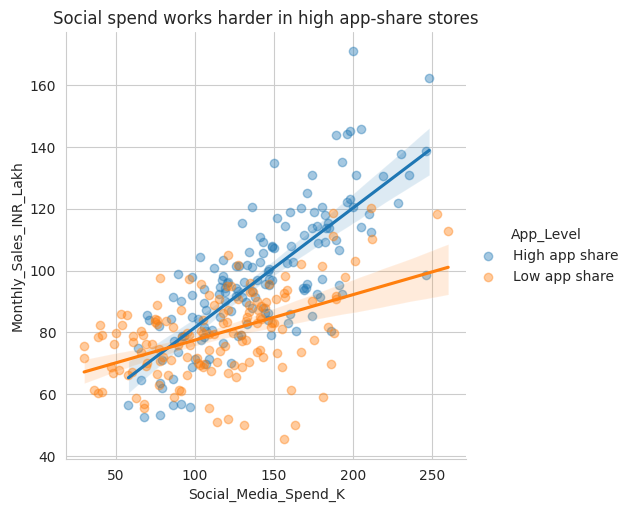

In [16]:
#STEP-3 checking the moderation effect Through visualization / linear model block
df["App_Level"] = np.where(df["App_Orders_Share_Pct"] > df["App_Orders_Share_Pct"].median(), "High app share", "Low app share")

g = sns.lmplot(data=df, x="Social_Media_Spend_K", y="Monthly_Sales_INR_Lakh", hue="App_Level", height=5, scatter_kws={"alpha": 0.4})

g.set(title="Social spend works harder in high app-share stores")

plt.show()

Principle component anaylsis

In [17]:
groups = {
    "Customer Experience": ["Taste_Score", "Service_Score", "Cleanliness_Score", "Ambience_Score", "Staff_Friendliness_Score"],
    "Digital Engagement": ["App_Orders_Share_Pct", "Loyalty_Members_K", "App_Rating", "Social_Followers_K"],
    "Marketing Intensity": ["Social_Media_Spend_K", "Outdoor_Ad_Spend_K", "Influencer_Spend_K", "Promo_Offers_Count"],
    "Store Capacity": ["Store_Area_SqFt", "Seats", "Staff_Count"],
}

for name, cols in groups.items():
    c = df[cols].corr().values
    average = (c.sum() - len(cols)) / (len(cols) * (len(cols) - 1))  # average correlation inside the group
    print(f"{name}: {len(cols)} variables, average correlation {average:.2f}")

Customer Experience: 5 variables, average correlation 0.79
Digital Engagement: 4 variables, average correlation 0.77
Marketing Intensity: 4 variables, average correlation 0.74
Store Capacity: 3 variables, average correlation 0.77


In [18]:
cols = ['Taste_Score', 'Service_Score', 'Cleanliness_Score', 'Ambience_Score', 'Staff_Friendliness_Score']
cust_exp_corr = df[cols].corr().round(2)
display(cust_exp_corr)

,Taste_Score,Service_Score,Cleanliness_Score,Ambience_Score,Staff_Friendliness_Score
Taste_Score,1.00,0.83,0.81,0.72,0.84
Service_Score,0.83,1.00,0.83,0.76,0.82
Cleanliness_Score,0.81,0.83,1.00,0.73,0.80
Ambience_Score,0.72,0.76,0.73,1.00,0.73
Staff_Friendliness_Score,0.84,0.82,0.80,0.73,1.00


PCA1 customer experience index

In [19]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

cols = groups["Customer Experience"]

# Step A: put every variable on the same scale
scaled = StandardScaler().fit_transform(df[cols])

# Step B: run PCA
pca = PCA()
scores = pca.fit_transform(scaled)

# Step C: how much does each component explain?
names = [f"PC{i+1}" for i in range(len(cols))]
print(pd.Series(pca.explained_variance_ratio_, index=names).round(2))

PC1    0.83
PC2    0.06
PC3    0.04
PC4    0.03
PC5    0.03
dtype: float64


In [20]:
# Step D: the loadings show how much each variable counts in PC1

sign = 1 if pca.components_[0].sum() > 0 else -1  # make sure a higher score means better

print(pd.Series(pca.components_[0] * sign, index=cols).round(2))

Taste_Score                 0.45
Service_Score               0.46
Cleanliness_Score           0.45
Ambience_Score              0.42
Staff_Friendliness_Score    0.45
dtype: float64


In [21]:
# Step E: turn PC1 into an index from 0 to 100

raw_index = scores[:, 0] * sign

df["Experience_Index"] = (raw_index - raw_index.min()) / (raw_index.max() - raw_index.min()) * 100

variance_explained = {"Experience_Index": round(pca.explained_variance_ratio_[0] * 100)}

print(df[["Store_ID", "Experience_Index"]].sort_values("Experience_Index").head(5).round(1))
df.head()

    Store_ID  Experience_Index
90    ST-091               0.0
56    ST-057              12.4
229   ST-230              13.4
114   ST-115              14.9
0     ST-001              15.1


,Store_ID,City,City_Tier,Location_Type,Store_Area_SqFt,Seats,Staff_Count,Social_Media_Spend_K,Outdoor_Ad_Spend_K,Influencer_Spend_K,...,Avg_Bill_INR,Repeat_Customer_Pct,Monthly_Sales_INR_Lakh,Social_c,App_c,Wait_c,Service_c,Is_Metro,App_Level,Experience_Index
0,ST-001,Hyderabad,Metro,Airport or Transit,790,37,9,129,136,46,...,281,35.3,79.2,0.636667,0.860667,-1.125333,-2.065667,1,High app share,15.053441
1,ST-002,Nagpur,Tier 3,High Street,1400,50,14,95,34,28,...,280,40.4,79.9,-33.363333,0.460667,0.074667,0.134333,0,Low app share,43.282122
2,ST-003,Kolkata,Metro,High Street,1120,44,10,76,78,53,...,362,46.1,84.1,-52.363333,-4.439333,-2.625333,1.834333,1,Low app share,95.125035
3,ST-004,Delhi NCR,Metro,High Street,1830,67,19,53,57,23,...,291,39.5,85.9,-75.363333,-5.839333,-1.325333,-0.165667,1,Low app share,48.250579
4,ST-005,Chennai,Metro,Mall,1300,54,13,198,103,94,...,296,37.5,123.0,69.636667,2.060667,-1.025333,-1.365667,1,High app share,31.811512


PCA2 Digital engagement index

In [22]:
def make_index(columns, index_name):
    scaled = StandardScaler().fit_transform(df[columns])
    pca = PCA().fit(scaled)
    scores = pca.transform(scaled)[:, 0]

    sign = 1 if pca.components_[0].sum() > 0 else -1
    scores = scores * sign

    df[index_name] = (scores - scores.min()) / (scores.max() - scores.min()) * 100
    variance_explained[index_name] = round(pca.explained_variance_ratio_[0] * 100)

    print("Variance explained by PC1:", variance_explained[index_name], "%")
    print(pd.Series(pca.components_[0] * sign, index=columns).round(2))


make_index(groups["Digital Engagement"], "Digital_Index")

Variance explained by PC1: 83 %
App_Orders_Share_Pct    0.51
Loyalty_Members_K       0.50
App_Rating              0.49
Social_Followers_K      0.51
dtype: float64


PCA3 Marketing intensity index

In [23]:
make_index(groups["Marketing Intensity"], "Marketing_Index")

Variance explained by PC1: 80 %
Social_Media_Spend_K    0.52
Outdoor_Ad_Spend_K      0.51
Influencer_Spend_K      0.49
Promo_Offers_Count      0.49
dtype: float64


PCA4 Store capacity index

In [24]:
make_index(groups["Store Capacity"], "Capacity_Index")

Variance explained by PC1: 85 %
Store_Area_SqFt    0.58
Seats              0.58
Staff_Count        0.57
dtype: float64


Checking coorelation for all the index

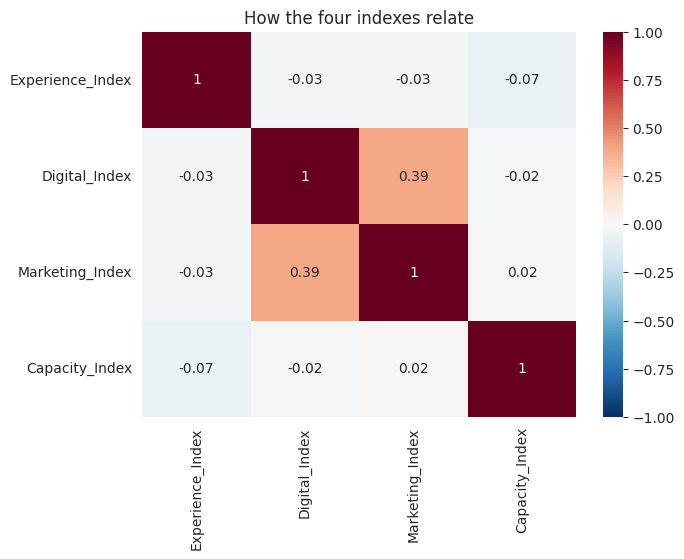

In [25]:
index_cols = ["Experience_Index", "Digital_Index", "Marketing_Index", "Capacity_Index"]

plt.figure(figsize=(7, 5))
sns.heatmap(df[index_cols].corr().round(2), annot=True, cmap="RdBu_r", vmin=-1, vmax=1)

plt.title("How the four indexes relate")
plt.show()